# Capítulo 2. Ecuaciones de primer orden
## Sección 2.4.1. Ecuaciones completamente no lineales y características generalizadas

**Fuente principal:** página 8 de `Ecuacione Lineales De Primer Orden.pdf`.

Se introduce

$$
F(x,y,u,p,q)=0,
$$

con

$$
p=u_x,
$$

$$
q=u_y.
$$

### Ejemplo gráfico complementario · Rayos normales al frente inicial

El círculo $r=1$ es el frente con valor cero para $u=r-1$. En el exterior, caminar radialmente una distancia $h$ aumenta $u$ exactamente en $h$. Caminar sobre un mismo círculo mantiene $u$ constante. Los radios son características porque apuntan en la dirección elegida por esta eikonal; los círculos son conjuntos de nivel. La conservación de $u$ de la ecuación de transporte homogénea era una propiedad de aquella ecuación.


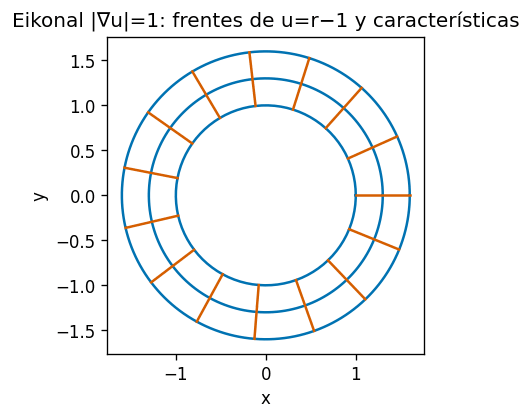

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.4,3.6))
theta=np.linspace(0,2*np.pi,180)
for radio in [1,1.3,1.6]:
    ax.plot(radio*np.cos(theta),radio*np.sin(theta),color="#0072B2")
for angulo in theta[::12]:
    ax.plot([np.cos(angulo),1.6*np.cos(angulo)],[np.sin(angulo),1.6*np.sin(angulo)],color="#D55E00")
ax.set(aspect="equal",xlabel="x",ylabel="y",title="Eikonal |∇u|=1: frentes de u=r−1 y características")
fig.tight_layout()
plt.show()

# 2.4.1. Transcripción organizada de las notas

**Complemento · Por qué aparecen cinco incógnitas.** Para $F(x,y,u,p,q)=0$ las componentes de la pendiente $p=u_x$, $q=u_y$ determinan hacia dónde continuar. En una solución $C^2$, derivar la identidad respecto de $x$ da $F_x+F_u p+F_p p_x+F_q p_y=0$, usando $q_x=p_y$. Si se escoge $(x_s,y_s)=(F_p,F_q)$, los dos últimos términos son precisamente $p_s$. Derivando respecto de $y$ se obtiene $q_s$. El sistema que sigue transporta tanto la altura como el plano tangente.


Las características generalizadas satisfacen

$$
x_s=F_p,
$$

$$
y_s=F_q,
$$

$$
u_s=pF_p+qF_q,
$$

$$
p_s=-F_x-pF_u,
$$

$$
q_s=-F_y-qF_u.
$$

Los datos iniciales son

$$
x(0)=\widetilde x(\xi),
$$

$$
y(0)=\widetilde y(\xi),
$$

$$
u(0)=f(\xi),
$$

$$
p(0)=\widetilde p(\xi),
$$

$$
q(0)=\widetilde q(\xi),
$$

y deben satisfacer

$$
F(
\widetilde x,
\widetilde y,
f,
\widetilde p,
\widetilde q
)=0.
$$


# 2.4.2. Desarrollo formal

## Definición 2.4.1 — Ecuación completamente no lineal

Una ecuación completamente no lineal tiene la forma

$$
F(x,y,u,u_x,u_y)=0.
$$

## Definición 2.4.2 — Sistema de Charpit

Introduciendo

$$
p=u_x,
$$

$$
q=u_y,
$$

se define

$$
\begin{cases}
x_s=F_p,\\
y_s=F_q,\\
u_s=pF_p+qF_q,\\
p_s=-F_x-pF_u,\\
q_s=-F_y-qF_u.
\end{cases}
$$

## Aclaración 2.4.3 — Ecuación para $u_s$

Por la regla de la cadena,

$$
u_s=u_xx_s+u_yy_s.
$$

Sustituyendo

$$
u_x=p,
$$

$$
u_y=q,
$$

$$
x_s=F_p,
$$

$$
y_s=F_q,
$$

resulta

$$
u_s=pF_p+qF_q.
$$

## Proposición 2.4.4 — Conservación de $F$

A lo largo de una característica generalizada,

$$
\frac{dF}{ds}=0.
$$

### Demostración

Se calcula

$$
\frac{dF}{ds}
=
F_xx_s+F_yy_s+F_uu_s+F_pp_s+F_qq_s.
$$

Al sustituir el sistema de Charpit, todos los términos se cancelan.

## Complemento 2.4.5 — Caso Hamiltoniano

Si $F$ no depende de $u$,

$$
x_s=F_p,
$$

$$
y_s=F_q,
$$

$$
p_s=-F_x,
$$

$$
q_s=-F_y.
$$

Estas son las ecuaciones canónicas de Hamilton para las variables $(x,y,p,q)$.

# 2.4.3. Ejemplo eikonal

Considere

$$
u_x^2+u_y^2=1.
$$

Entonces

$$
F(p,q)=p^2+q^2-1.
$$

El sistema es

$$
x_s=2p,
$$

$$
y_s=2q,
$$

$$
u_s=2p^2+2q^2,
$$

$$
p_s=0,
$$

$$
q_s=0.
$$

Sobre $F=0$,

$$
p^2+q^2=1
$$

y

$$
u_s=2.
$$

Las proyecciones características son rectas.

# 2.4.4. Visualización Manim

Se visualizan las características de la ecuación eikonal. Una curva inicial emite rayos normales unitarios. Los ejes, la curva y los datos permanecen visibles durante cuatro segundos.

In [ ]:
import os
import shutil
import tempfile
import uuid
from pathlib import Path

def miktex_candidates():
    candidates = []
    for base in (
        os.environ.get("LOCALAPPDATA"),
        os.environ.get("ProgramFiles"),
        os.environ.get("ProgramFiles(x86)"),
    ):
        if not base:
            continue
        root = Path(base)
        candidates.extend([
            root / "Programs" / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "Programs" / "MiKTeX" / "miktex" / "bin",
            root / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "MiKTeX" / "miktex" / "bin",
        ])
    return candidates

for candidate in miktex_candidates():
    if candidate.exists():
        os.environ["PATH"] = (
            str(candidate)
            + os.pathsep
            + os.environ.get("PATH", "")
        )

latex_exe = shutil.which("latex")
dvisvgm_exe = shutil.which("dvisvgm")

if latex_exe is None or dvisvgm_exe is None:
    raise RuntimeError(
        "No se encontraron latex.exe y dvisvgm.exe. "
        "Abre MiKTeX Console, completa la instalación y reinicia el kernel."
    )

from manim import config, __version__ as manim_version

TEX_RUNTIME_DIR = (
    Path(tempfile.gettempdir())
    / f"manim_tex_recuperado_{os.getpid()}_{uuid.uuid4().hex[:10]}"
)
TEX_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"

print(f"Manim Community: {manim_version}")
print("latex   :", latex_exe)
print("dvisvgm :", dvisvgm_exe)
print("TeX dir :", TEX_RUNTIME_DIR)
print("Render preparado: 2560×1440, 120 fps")
print("La animación no ha sido compilada.")

In [ ]:
%%manim -v WARNING -r 2560,1440 --fps 120 CaracteristicasGeneralizadasEikonal

from manim import *
import numpy as np

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"


class CaracteristicasGeneralizadasEikonal(Scene):
    def construct(self):
        self.camera.background_color = "#0B1020"

        title = Text(
            "Características generalizadas de la ecuación eikonal",
            font_size=39,
            weight=BOLD,
        ).to_edge(UP, buff=0.18)

        formula = MathTex(
            r"F(p,q)=p^2+q^2-1",
            r"\qquad",
            r"(x_s,y_s)=(2p,2q)",
            font_size=34,
            color=YELLOW_C,
        ).next_to(title, DOWN, buff=0.12)

        axes = Axes(
            x_range=[-5, 5, 1],
            y_range=[-3.5, 4, 1],
            x_length=10.4,
            y_length=6.2,
            tips=False,
        ).shift(0.35 * DOWN)

        curve = ParametricFunction(
            lambda r: axes.c2p(r, 0.42 * np.sin(1.2 * r)),
            t_range=[-3.5, 3.5],
            color=ORANGE,
            stroke_width=6,
        )

        seeds = np.linspace(-3.2, 3.2, 13)

        data = []
        for r in seeds:
            slope = 0.504 * np.cos(1.2 * r)
            normal = np.array([-slope, 1.0])
            normal = normal / np.linalg.norm(normal)
            point = np.array([r, 0.42 * np.sin(1.2 * r)])
            data.append((point, normal))

        normals = VGroup(*[
            Arrow(
                axes.c2p(point[0], point[1]),
                axes.c2p(
                    point[0] + 0.55 * normal[0],
                    point[1] + 0.55 * normal[1],
                ),
                buff=0,
                color=GREEN_C,
                stroke_width=3,
            )
            for point, normal in data
        ])

        rays = VGroup(*[
            Line(
                axes.c2p(point[0], point[1]),
                axes.c2p(
                    point[0] + 4.6 * normal[0],
                    point[1] + 4.6 * normal[1],
                ),
                color=BLUE_B,
                stroke_width=2.2,
                stroke_opacity=0.58,
            )
            for point, normal in data
        ])

        particles = VGroup(*[
            Dot(
                axes.c2p(point[0], point[1]),
                radius=0.06,
                color=PINK,
            )
            for point, normal in data
        ])

        tracker = ValueTracker(0.0)

        for dot, (point, normal) in zip(particles, data):
            dot.add_updater(
                lambda mob, point=point, normal=normal: mob.move_to(
                    axes.c2p(
                        point[0] + 2 * tracker.get_value() * normal[0],
                        point[1] + 2 * tracker.get_value() * normal[1],
                    )
                )
            )

        s_number = DecimalNumber(
            0.0,
            num_decimal_places=2,
            font_size=30,
            color=GREEN_C,
        )
        s_number.add_updater(
            lambda mob: mob.set_value(tracker.get_value())
        )

        display = VGroup(
            MathTex(r"s=", font_size=30, color=GREEN_C),
            s_number,
            MathTex(
                r"p^2+q^2=1",
                font_size=31,
                color=YELLOW_C,
            ),
        ).arrange(RIGHT, buff=0.16).to_edge(DOWN, buff=0.20)

        self.play(
            FadeIn(title),
            Write(formula),
            Create(axes),
            Create(curve),
            LaggedStart(
                *[GrowArrow(arrow) for arrow in normals],
                lag_ratio=0.05,
            ),
            FadeIn(particles),
            FadeIn(display),
            run_time=3.0,
        )

        self.wait(4.0)

        self.play(FadeIn(rays), run_time=1.5)

        self.play(
            tracker.animate.set_value(2.1),
            run_time=12.0,
            rate_func=linear,
        )

        self.wait(3.0)

        for dot in particles:
            dot.clear_updaters()
        s_number.clear_updaters()

# 2.4.5. Ejercicios propuestos

1. Verifique explícitamente que $dF/ds=0$ para el sistema de Charpit.

2. Obtenga el sistema para
   $$
   u_x^2+u_y-u=0.
   $$

3. Para
   $$
   u_t+\frac12u_x^2=0,
   $$
   derive el sistema hamiltoniano.

4. Resuelva las características de
   $$
   4u_x^2+u_y^2=1.
   $$

# Revisión

Se recuperaron la formulación completamente no lineal, el sistema de Charpit, la conservación de $F$, la relación hamiltoniana y el ejemplo eikonal.

La siguiente sección determina las pendientes iniciales compatibles y la transversalidad generalizada.